It is possible to be delta neutral in a variety of ways: selling underlying, buying puts (if long calls) at the same strike/expiry (which is a straddle) buying puts at different times to expiry, or any combination of the above. Each delta hedging strategy gives different greek exposures, for example: trading underlying doesn't affect our gamma or vega position, entering straddles will increase our gamma and vega sensitivity.

- Condor the price is between lowest and highest, of course. Approximately delta neutral between the two strikes

## Long straddle: value and Greeks across expiries

Buy one call and one put with the same strike (100) and expiry.
Hold annual volatility at 20%, with zero interest and dividends, and compare 180, 90, 30 and 7 days remaining.

Straddles are not delta neutral because the delta of the call and put are different (an ITM call will have a greater |delta| than and OTM put). For example, if the call is delta 75 and the put is delta -25 we are left with a 50 delta exposure, this is known as a bull straddle (still long the underlying). If we purchase 3 puts and 1 call we will be delta neutral, as we are no longer one-to-one this position is known as a ratio straddle.

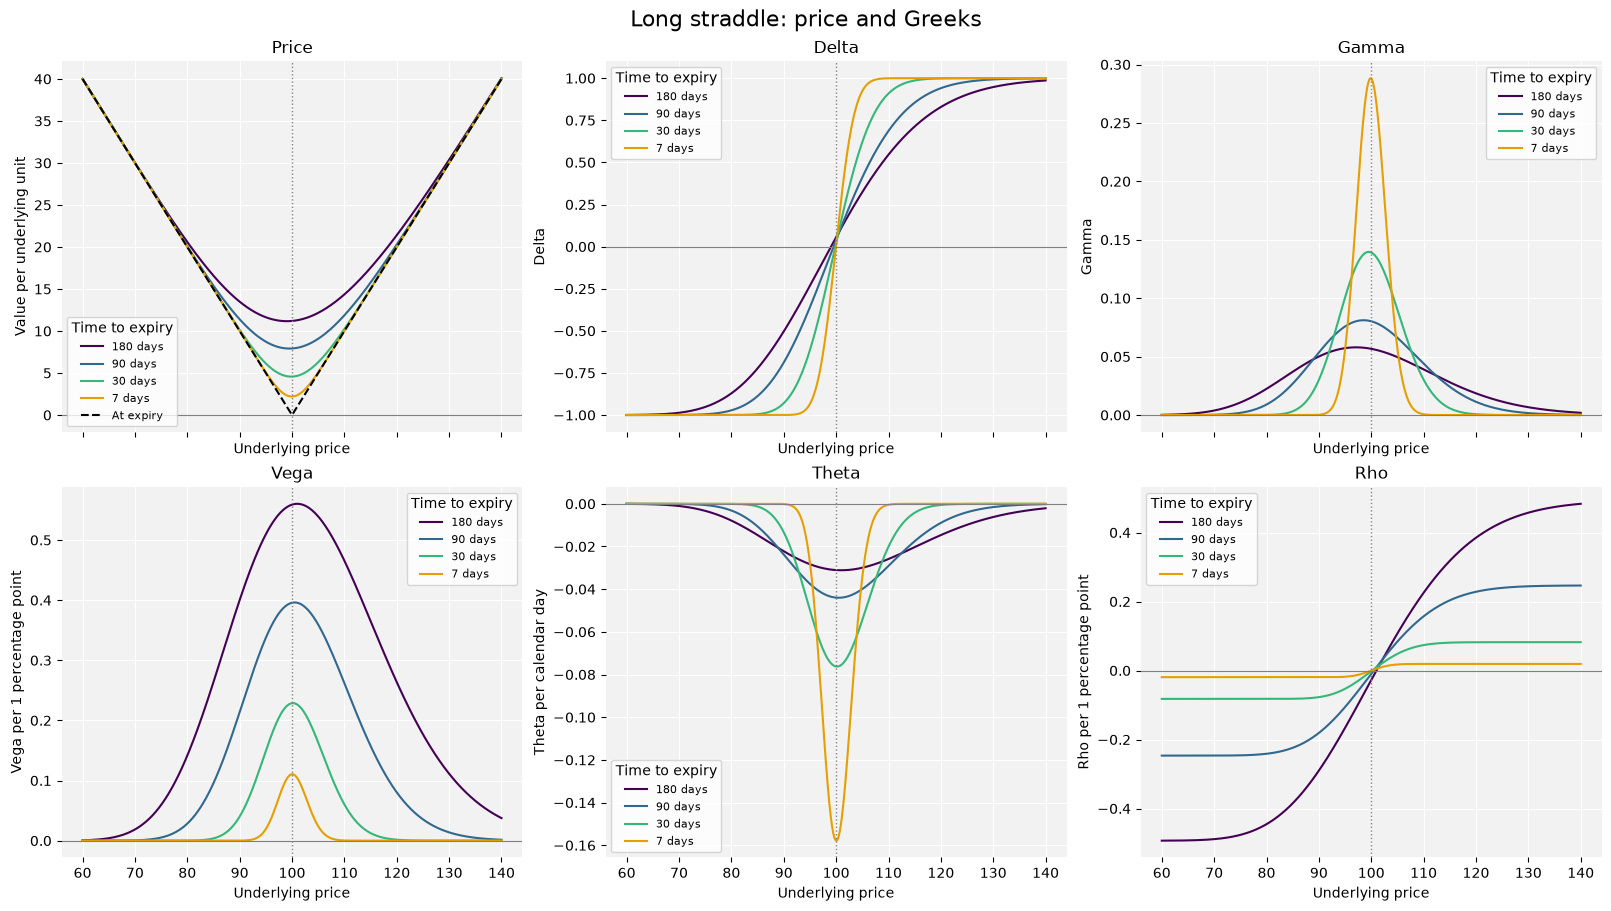

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from straddles import Call, Put

strike = 100
volatility = 0.20
rate = 0.0
dividend = 0.0
expiry_days = [180, 90, 30, 7]
initial_days = max(expiry_days)
spot = np.linspace(60, 140, 801)
colors = ["#440154", "#31688e", "#35b779", "#e69f00"]

straddle = Call(strike, initial_days / 365, volatility) + Put(
    strike, initial_days / 365, volatility
)
metrics = [
    ("theo", "Price", "Value per underlying unit", 1),
    ("delta", "Delta", "Delta", 1),
    ("gamma", "Gamma", "Gamma", 1),
    ("vega", "Vega", "Vega per 1 percentage point", 100),
    ("theta", "Theta", "Theta per calendar day", 365),
    ("rho", "Rho", "Rho per 1 percentage point", 100),
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharex=True, layout="constrained")
for days, color in zip(expiry_days, colors):
    values = straddle.evaluate(
        spot,
        elapsed=(initial_days - days) / 365,
        rate=rate,
        dividend=dividend,
    )
    for ax, (metric, title, ylabel, scale) in zip(axes.flat, metrics):
        ax.plot(spot, values[metric] / scale, color=color, label=f"{days} days")

axes[0, 0].plot(
    spot,
    straddle.theo(spot, elapsed=initial_days / 365),
    color="black",
    linestyle="--",
    label="At expiry",
)
for ax, (_, title, ylabel, _) in zip(axes.flat, metrics):
    ax.set(title=title, xlabel="Underlying price", ylabel=ylabel)
    ax.axvline(strike, color="grey", linestyle=":", linewidth=1)
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.set_facecolor("#f2f2f2")
    ax.grid(color="white")
    ax.set_axisbelow(True)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.legend(title="Time to expiry", fontsize=8)

fig.suptitle("Long straddle: price and Greeks", fontsize=16)
plt.show()

## Long strangle: value and Greeks across expiries

A straddle is entered when the strike of the call is greater than that of the other put and call. This leaves a section of the underlying whereby the payoff does not change. Therefore close to expiry, if the underlying moves within the zero payoff section it might not effect the payoff. This causes the theta and gamma to go to zero in this region close to expiry. The vega is also less affected in this region close to expiry.


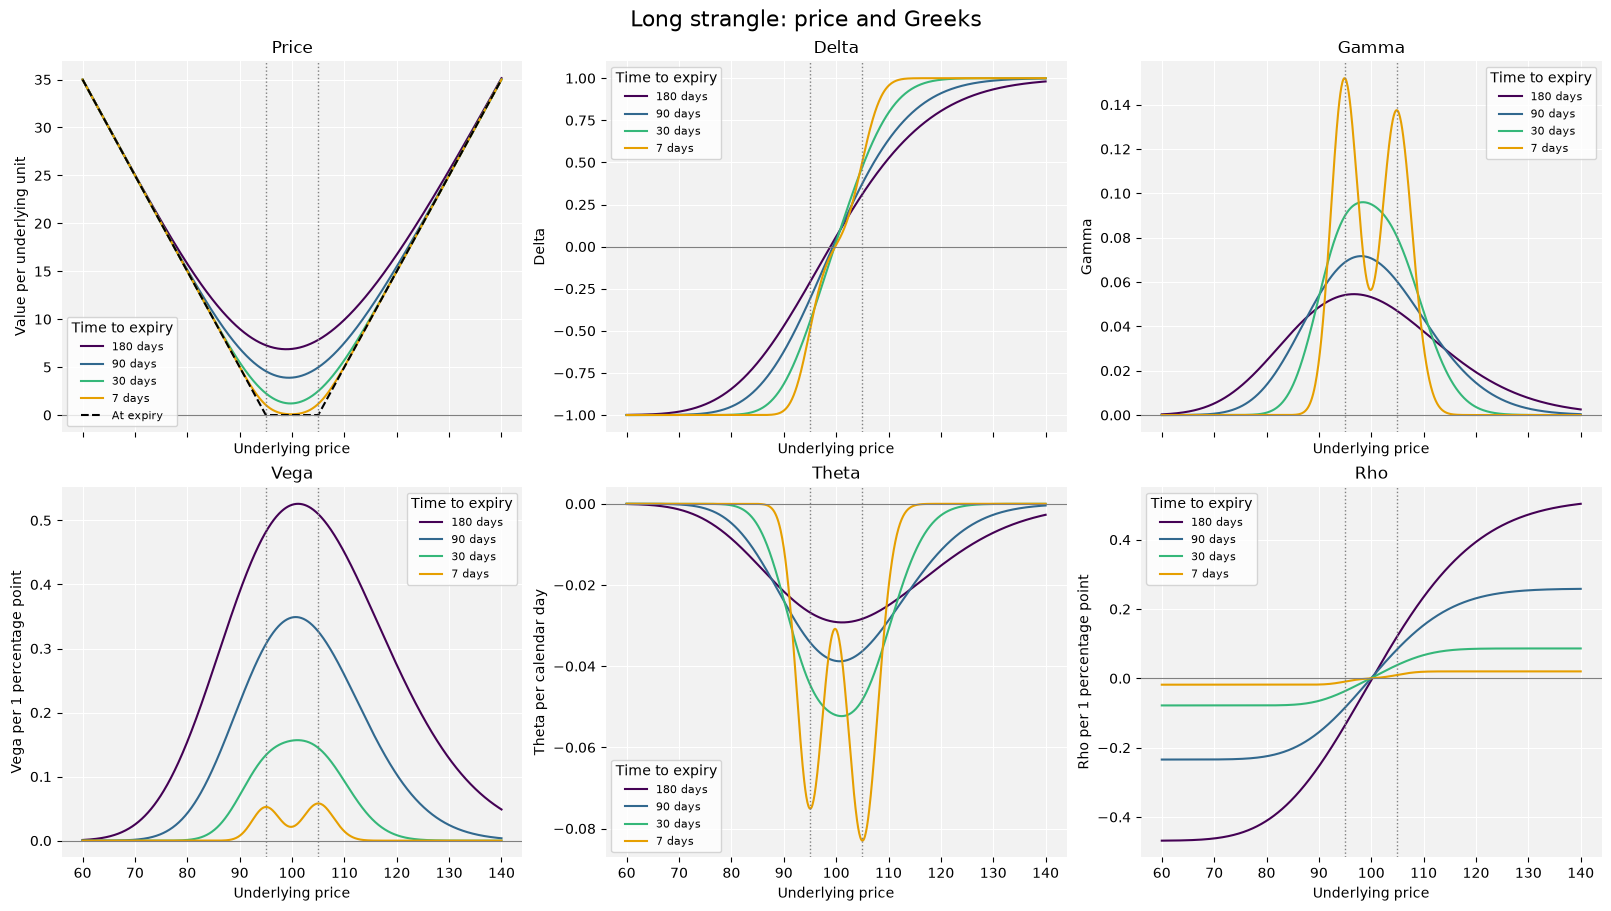

In [2]:
import matplotlib.pyplot as plt
import numpy as np

from straddles import Call, Put

put_strike = 95
call_strike = 105
volatility = 0.20
rate = 0.0
dividend = 0.0
expiry_days = [180, 90, 30, 7]
initial_days = max(expiry_days)
spot = np.linspace(60, 140, 801)
colors = ["#440154", "#31688e", "#35b779", "#e69f00"]

strangle = Put(put_strike, initial_days / 365, volatility) + Call(
    call_strike, initial_days / 365, volatility
)
metrics = [
    ("theo", "Price", "Value per underlying unit", 1),
    ("delta", "Delta", "Delta", 1),
    ("gamma", "Gamma", "Gamma", 1),
    ("vega", "Vega", "Vega per 1 percentage point", 100),
    ("theta", "Theta", "Theta per calendar day", 365),
    ("rho", "Rho", "Rho per 1 percentage point", 100),
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharex=True, layout="constrained")
for days, color in zip(expiry_days, colors):
    values = strangle.evaluate(
        spot,
        elapsed=(initial_days - days) / 365,
        rate=rate,
        dividend=dividend,
    )
    for ax, (metric, title, ylabel, scale) in zip(axes.flat, metrics):
        ax.plot(spot, values[metric] / scale, color=color, label=f"{days} days")

axes[0, 0].plot(
    spot,
    strangle.theo(spot, elapsed=initial_days / 365),
    color="black",
    linestyle="--",
    label="At expiry",
)
for ax, (_, title, ylabel, _) in zip(axes.flat, metrics):
    ax.set(title=title, xlabel="Underlying price", ylabel=ylabel)
    for strike in (put_strike, call_strike):
        ax.axvline(strike, color="grey", linestyle=":", linewidth=1)
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.set_facecolor("#f2f2f2")
    ax.grid(color="white")
    ax.set_axisbelow(True)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.legend(title="Time to expiry", fontsize=8)

fig.suptitle("Long strangle: price and Greeks", fontsize=16)
plt.show()

## Long call butterfly: value and Greeks across expiries

Some traders do not like the unlimited loss(/payoff) arising from a (short) straddle postion, a butterfly helps mitigate that. Purchasing a call, then selling two calls and finally purchasing a call again to be neutral enables this,

The equally spaced strikes give a tent-shaped
expiry payoff, highest at the middle strike and zero outside the wings.
Hold annual volatility at 20%, with zero interest and dividends, and compare
180, 90, 30 and 7 days remaining.

In this instance, the payoff is certainly between 0 and 10, therefore the fair price of entering this position should be between those values. The actual value will be determined by the distribution of underlying prices at expiry.

This position is short volatility and gamma and long theta within the strikes, as the portfolio is in the money between the strikes, otherside that range volatility is good as it gives increased probability of expiring in the money.

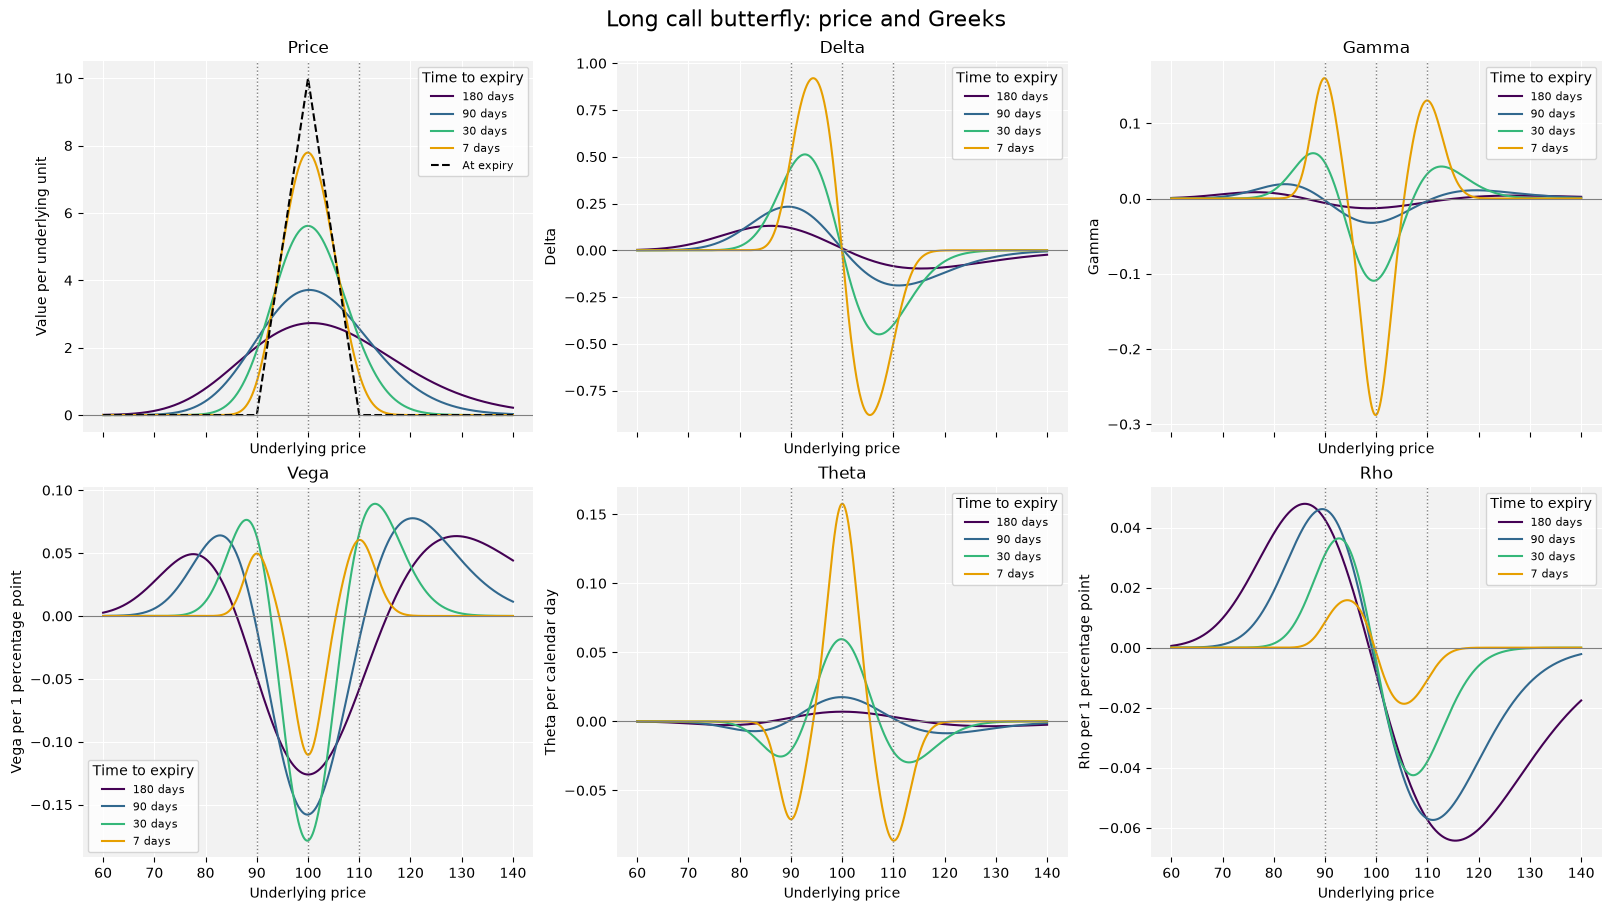

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

from straddles import Call, Put

strikes = [90, 100, 110]
volatility = 0.20
rate = 0.0
dividend = 0.0
expiry_days = [180, 90, 30, 7]
initial_days = max(expiry_days)
spot = np.linspace(60, 140, 801)
colors = ["#440154", "#31688e", "#35b779", "#e69f00"]

butterfly = (
    Call(strikes[0], initial_days / 365, volatility)
    - 2 * Call(strikes[1], initial_days / 365, volatility)
    + Call(strikes[2], initial_days / 365, volatility)
)
metrics = [
    ("theo", "Price", "Value per underlying unit", 1),
    ("delta", "Delta", "Delta", 1),
    ("gamma", "Gamma", "Gamma", 1),
    ("vega", "Vega", "Vega per 1 percentage point", 100),
    ("theta", "Theta", "Theta per calendar day", 365),
    ("rho", "Rho", "Rho per 1 percentage point", 100),
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharex=True, layout="constrained")
for days, color in zip(expiry_days, colors):
    values = butterfly.evaluate(
        spot,
        elapsed=(initial_days - days) / 365,
        rate=rate,
        dividend=dividend,
    )
    for ax, (metric, title, ylabel, scale) in zip(axes.flat, metrics):
        ax.plot(spot, values[metric] / scale, color=color, label=f"{days} days")

axes[0, 0].plot(
    spot,
    butterfly.theo(spot, elapsed=initial_days / 365),
    color="black",
    linestyle="--",
    label="At expiry",
)
for ax, (_, title, ylabel, _) in zip(axes.flat, metrics):
    ax.set(title=title, xlabel="Underlying price", ylabel=ylabel)
    for strike in strikes:
        ax.axvline(strike, color="grey", linestyle=":", linewidth=1)
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.set_facecolor("#f2f2f2")
    ax.grid(color="white")
    ax.set_axisbelow(True)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.legend(title="Time to expiry", fontsize=8)

fig.suptitle("Long call butterfly: price and Greeks", fontsize=16)
plt.show()

## Long call condor: value and Greeks across expiries

A condor enables similar to the butterfly with a region of fixed payoff in the middle instead of a tent shape. 

Buy calls at strikes 90 and 110 and sell calls at strikes 95 and 105, with one
of each and the same expiry.
Hold annual volatility at 20%, with zero interest and dividends, and compare
180, 90, 30 and 7 days remaining.


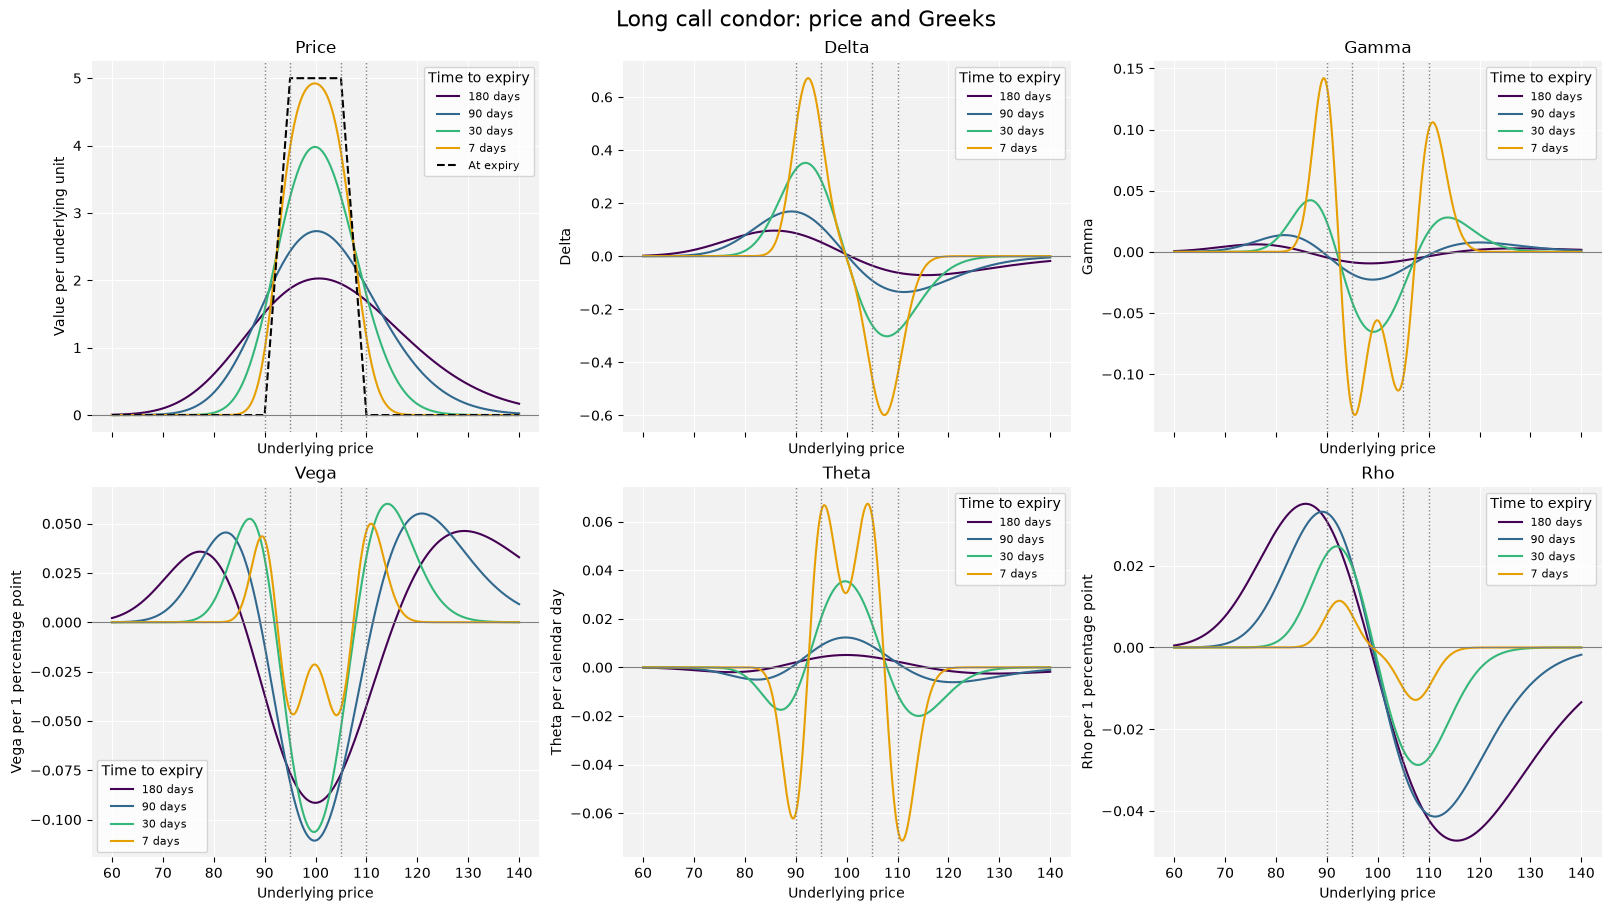

In [3]:
import matplotlib.pyplot as plt
import numpy as np

from straddles import Call, Put

strikes = [90, 95, 105, 110]
volatility = 0.20
rate = 0.0
dividend = 0.0
expiry_days = [180, 90, 30, 7]
initial_days = max(expiry_days)
spot = np.linspace(60, 140, 801)
colors = ["#440154", "#31688e", "#35b779", "#e69f00"]

condor = (
    Call(strikes[0], initial_days / 365, volatility)
    - Call(strikes[1], initial_days / 365, volatility)
    - Call(strikes[2], initial_days / 365, volatility)
    + Call(strikes[3], initial_days / 365, volatility)
)
metrics = [
    ("theo", "Price", "Value per underlying unit", 1),
    ("delta", "Delta", "Delta", 1),
    ("gamma", "Gamma", "Gamma", 1),
    ("vega", "Vega", "Vega per 1 percentage point", 100),
    ("theta", "Theta", "Theta per calendar day", 365),
    ("rho", "Rho", "Rho per 1 percentage point", 100),
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharex=True, layout="constrained")
for days, color in zip(expiry_days, colors):
    values = condor.evaluate(
        spot,
        elapsed=(initial_days - days) / 365,
        rate=rate,
        dividend=dividend,
    )
    for ax, (metric, title, ylabel, scale) in zip(axes.flat, metrics):
        ax.plot(spot, values[metric] / scale, color=color, label=f"{days} days")

axes[0, 0].plot(
    spot,
    condor.theo(spot, elapsed=initial_days / 365),
    color="black",
    linestyle="--",
    label="At expiry",
)
for ax, (_, title, ylabel, _) in zip(axes.flat, metrics):
    ax.set(title=title, xlabel="Underlying price", ylabel=ylabel)
    for strike in strikes:
        ax.axvline(strike, color="grey", linestyle=":", linewidth=1)
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.set_facecolor("#f2f2f2")
    ax.grid(color="white")
    ax.set_axisbelow(True)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.legend(title="Time to expiry", fontsize=8)

fig.suptitle("Long call condor: price and Greeks", fontsize=16)
plt.show()

Being long straddle/strange or short butterfly/conder are all +gamma, +vega, -theta positions.